# EDA 

## 1. Imports et chargement

In [27]:
%pip install pandas numpy scipy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Style visuel simple
sns.set_theme(style="whitegrid")

# chargement du dataset
df = pd.read_csv('../Base.csv')

print(f"Dataset complet assemblé : {df.shape[0]} lignes et {df.shape[1]} colonnes.")

Dataset complet assemblé : 1000000 lignes et 32 colonnes.


## 2. Qualité des données

In [29]:
# Codes d'absence : -1 est un code (pas une valeur) sur ces 5 colonnes
cols_manquants = ['prev_address_months_count', 'current_address_months_count', 'bank_months_count',
                  'session_length_in_minutes', 'device_distinct_emails_8w']
df_clean = df.copy()
df_clean[cols_manquants] = df_clean[cols_manquants].replace(-1, np.nan)

# intended_balcon_amount : les négatifs codent l'absence (74 % des lignes) -> NaN, pas 0
masque_neg = df_clean['intended_balcon_amount'] < 0
print(f"intended_balcon_amount < 0 : {masque_neg.sum()} lignes ({masque_neg.mean()*100:.1f} %)")
df_clean.loc[masque_neg, 'intended_balcon_amount'] = np.nan

# credit_risk_score : on garde -1, c'est une valeur ordinaire (pas de pic isolé)
print(df['credit_risk_score'].value_counts().loc[[-3, -2, -1, 0, 1, 2]])

na = df_clean.isna().sum()
na = na[na > 0]
print(pd.DataFrame({'Absolue': na, '%': (na / len(df_clean) * 100).round(2)}))
print("velocity_6h négatives :", (df['velocity_6h'] < 0).sum(), "| min :", round(df['velocity_6h'].min(), 1))

intended_balcon_amount < 0 : 742523 lignes (74.3 %)
credit_risk_score
-3    440
-2    473
-1    488
 0    524
 1    552
 2    644
Name: count, dtype: int64
                              Absolue      %
prev_address_months_count      712920  71.29
current_address_months_count     4254   0.43
intended_balcon_amount         742523  74.25
bank_months_count              253635  25.36
session_length_in_minutes        2015   0.20
device_distinct_emails_8w         359   0.04
velocity_6h négatives : 44 | min : -170.6


**Constat** : -1 est un code d'absence sur 5 colonnes (prev_address_months_count, current_address_months_count, bank_months_count, session_length_in_minutes, device_distinct_emails_8w) : remplacé par NaN. Pour intended_balcon_amount, les valeurs négatives (74 % des dossiers) codent aussi l'absence (documentation Feedzai) : NaN et non 0, car un montant « 0 » serait une information inventée. credit_risk_score garde ses -1 : les effectifs voisins (-2 : 473, -1 : 488, 0 : 524) montrent une valeur ordinaire du score, pas un code.

**Pourquoi c'est important** : l'absence est elle-même informative (fraude 1,31 % si le montant est absent, 0,50 % sinon). La remplacer par 0 ou par la médiane sans indicateur la ferait disparaître.

**Conséquence modèle** : imputation par la médiane avec add_indicator=True pour conserver le drapeau « absent ». 44 valeurs négatives de velocity_6h (min -170) sont laissées telles quelles : trop rares pour peser.

In [30]:
df_clean.to_csv('../data/dataset_clean.csv', index=False)
print(df_clean.shape)  # doit afficher (1000000, 32)

(1000000, 32)


## 3. EDA Univarié (variable cible)

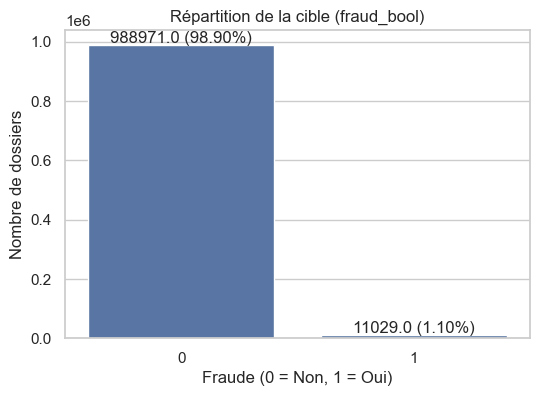

Taux de fraude dans le jeu de données : 1.10%


In [31]:
# Proportion de la cible
taux = df_clean['fraud_bool'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x='fraud_bool')
plt.title('Répartition de la cible (fraud_bool)')
plt.xlabel('Fraude (0 = Non, 1 = Oui)')
plt.ylabel('Nombre de dossiers')

for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df_clean)*100:.2f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

print(f"Taux de fraude dans le jeu de données : {taux[1]:.2f}%")

Le jeu contient 1,1 % de fraude : très déséquilibré. 

Un modèle qui prédit toujours « pas de fraude » a 98,9 % d'exactitude (accuracy) mais détecte 0 % des fraudes, d'où l'exclusion de l'accuracy. 

Le taux n'est pas stable : de 0,87 % (mois 2) à 1,47 % (mois 7). Le test (mois 6-7) contient donc plus de fraudes (1,40 %) que l'entraînement (1,03 %), et les PR-AUC ne sont comparables qu'à prévalence égale : d'où la comparaison avec le modèle naïf. 

Critère retenu : rappel à FPR ≤ 5 %.

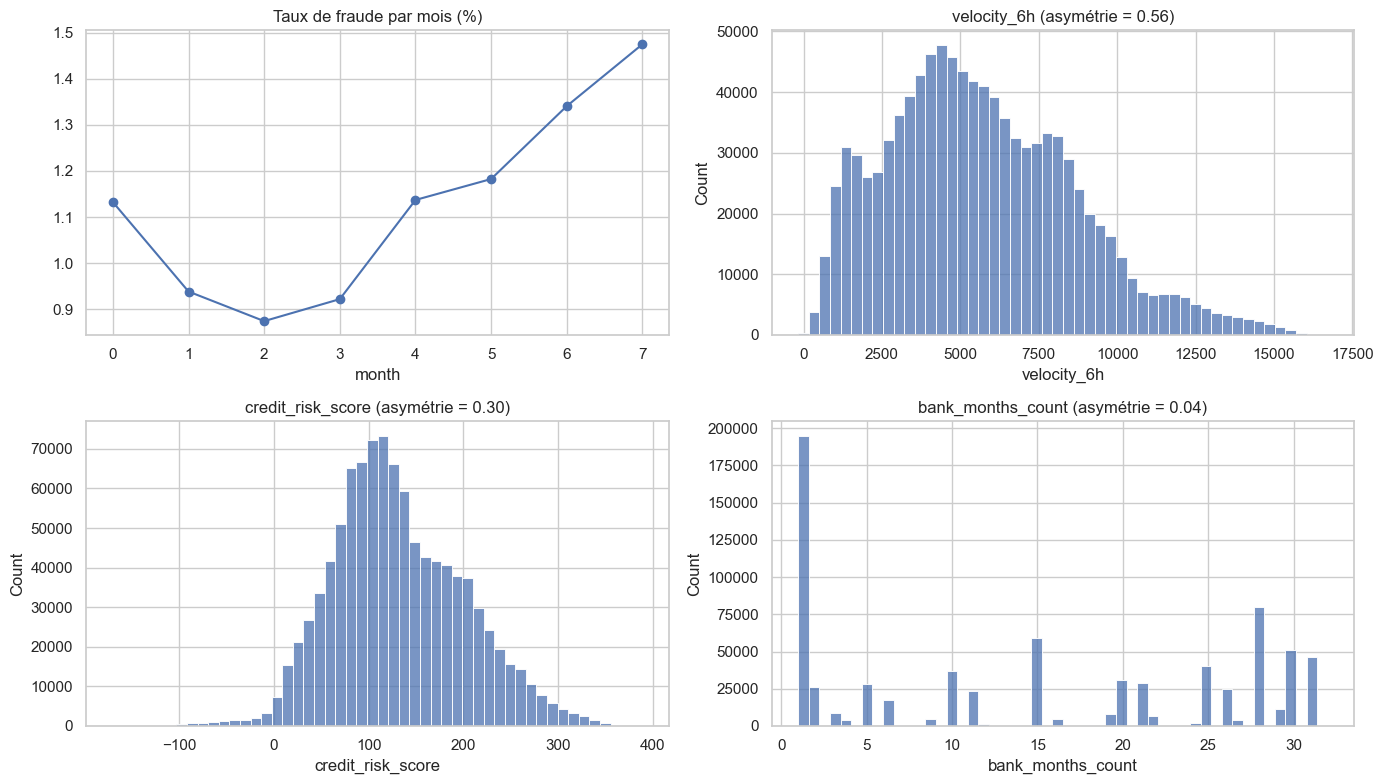

In [32]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax = ax.flatten()

(df_clean.groupby('month')['fraud_bool'].mean() * 100).plot(marker='o', ax=ax[0])
ax[0].set_title('Taux de fraude par mois (%)')

for a, col in zip(ax[1:], ['velocity_6h', 'credit_risk_score', 'bank_months_count']):
    sns.histplot(df_clean[col].dropna(), bins=50, ax=a)
    a.set_title(f"{col} (asymétrie = {df_clean[col].skew():.2f})")

plt.tight_layout()
plt.show()

**Forme des distributions** : Le taux de fraude varie au fil des mois (d'environ 1,13 % au mois 0, descendant à 0,88 % au mois 2, avant de monter jusqu'à près de 1,5 % au mois 7), reflétant une dynamique temporelle marquée.

**Forme et asymétrie** : Les variables présentées affichent des étalements et une asymétrie marqués (par exemple velocity_6h avec un étalement à droite, ou bank_months_count avec un pic fort vers 1-2 mois).

**Justification de la médiane** : En présence de cette asymétrie et de valeurs extrêmes sur les variables numériques, la moyenne subirait un biais important. La médiane constitue la mesure de tendance centrale la plus stable et robuste pour imputer les valeurs manquantes sans déformer les distributions.

## 4. Analyse bivariée : fonction d'analyse des hypothèses 

In [33]:
def analyser_distribution_continue(df, col, titre_hypothese):
    sub = df[[col, 'fraud_bool']].dropna()
    f = sub[sub['fraud_bool'] == 1][col]
    s = sub[sub['fraud_bool'] == 0][col]
    n1, n2 = len(f), len(s)

    plt.figure(figsize=(6, 4))
    sns.boxplot(data=sub, x='fraud_bool', y=col, showfliers=False)
    plt.title(f"{titre_hypothese} : {col}")
    plt.show()

    stat, p_val = stats.mannwhitneyu(f, s)
    auc_mw = stat / (n1 * n2)
    Q1, Q2 = auc_mw / (2 - auc_mw), 2 * auc_mw**2 / (1 + auc_mw)      # IC de l'AUC : Hanley-McNeil
    se_auc = np.sqrt((auc_mw*(1-auc_mw) + (n1-1)*(Q1-auc_mw**2) + (n2-1)*(Q2-auc_mw**2)) / (n1*n2))
    d = (f.mean() - s.mean()) / np.sqrt((f.std()**2 + s.std()**2) / 2)
    diff, se = f.mean() - s.mean(), np.sqrt(f.var()/n1 + s.var()/n2)

    print(f"RÉSULTATS : {titre_hypothese} ({col})")
    print(f"Médiane Fraude : {f.median():.2f} | Médiane Légitime : {s.median():.2f}")
    print(f"AUC Mann-Whitney : {auc_mw:.3f} | IC 95 % [{auc_mw-1.96*se_auc:.3f} ; {auc_mw+1.96*se_auc:.3f}] (0,5 = aucune différence)")
    print(f"d de Cohen : {d:.3f} | IC 95 % de la différence de moyennes [{diff-1.96*se:.2f} ; {diff+1.96*se:.2f}]")
    print(f"p-value : {p_val:.2e}\n")
    return auc_mw, p_val

#### Hypothèse 1:

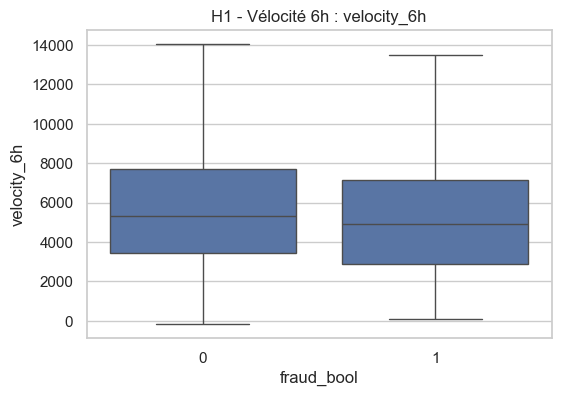

RÉSULTATS : H1 - Vélocité 6h (velocity_6h)
Médiane Fraude : 4916.46 | Médiane Légitime : 5324.54
AUC Mann-Whitney : 0.454 | IC 95 % [0.449 ; 0.460] (0,5 = aucune différence)
d de Cohen : -0.165 | IC 95 % de la différence de moyennes [-541.24 ; -432.26]
p-value : 3.89e-61



In [34]:
# Appel unique pour H1
auc_h1, p_h1 = analyser_distribution_continue(df_clean, 'velocity_6h', 'H1 - Vélocité 6h')

##### Résultat H1 (Vélocité) : INFIRMÉE

Constat chiffré : H1 est infirmée dans le sens attendu. Les demandes frauduleuses ont une vélocité sur 6h légèrement plus basse que les légitimes (médiane 4 916 vs 5 325 ; d=−0,16 ; IC 95 % [−541;−432]).

Taille d'effet : L'effet est très faible : l'AUC Mann-Whitney de 0,45 indique qu'une demande frauduleuse n'a que 45 % de chances d'avoir une vélocité supérieure à une demande légitime.

Lecture métier : L'hypothèse d'une attaque automatisée par botnet à haute fréquence n'est pas confirmée à l'ouverture de compte.

Conséquence modèle : La variable est conservée dans le pipeline mais apporte un pouvoir séparateur limité.

#### Hypothèse 2 : 

In [35]:
def analyser_h2_manquants(df, cols):
    """Pour chaque variable : taux de fraude si manquant vs renseigné, risque relatif (RR), IC 95 %, chi²."""
    resultats = []
    for col in cols:
        manq = df[col].isna()
        a, n1 = df.loc[manq, 'fraud_bool'].sum(), manq.sum()
        c, n2 = df.loc[~manq, 'fraud_bool'].sum(), (~manq).sum()
        t1, t0 = a / n1, c / n2
        rr = t1 / t0
        se_log = np.sqrt(1/a - 1/n1 + 1/c - 1/n2)
        lo, hi = np.exp(np.log(rr) - 1.96 * se_log), np.exp(np.log(rr) + 1.96 * se_log)
        _, p_val, _, _ = stats.chi2_contingency(pd.crosstab(manq, df['fraud_bool']))
        print(f"H2 - absence de {col} ({manq.mean()*100:.1f} % des dossiers)")
        print(f"Taux de fraude si manquant : {t1*100:.2f} % | si renseigné : {t0*100:.2f} %")
        print(f"Risque relatif : {rr:.2f} | IC 95 % [{lo:.2f} ; {hi:.2f}] | p (chi²) : {p_val:.1e}\n")
        resultats.append((col, rr, lo, hi))

    # Graphique : risque relatif et IC 95 % (1 = aucun effet)
    fig, ax = plt.subplots(figsize=(7, 3 + 0.4 * len(cols)))
    for i, (col, rr, lo, hi) in enumerate(resultats):
        ax.errorbar(rr, i, xerr=[[rr - lo], [hi - rr]], fmt='o', color='#2F6690', capsize=4)
        ax.text(hi + 0.1, i, f"{rr:.2f} [{lo:.2f} ; {hi:.2f}]", va='center', fontsize=9)
    ax.axvline(1, color='grey', ls='--')
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels([f"Absence de {c}" for c in cols])
    ax.set_xlabel('Risque relatif de fraude (absence vs valeur renseignée)')
    ax.set_title("H2 : l'absence d'information est liée à la fraude (p < 0,001)")
    ax.set_xlim(0, max(r[3] for r in resultats) + 1.6)
    plt.tight_layout()
    plt.show()

H2 - absence de bank_months_count (25.4 % des dossiers)
Taux de fraude si manquant : 1.63 % | si renseigné : 0.92 %
Risque relatif : 1.77 | IC 95 % [1.70 ; 1.84] | p (chi²) : 9.7e-192

H2 - absence de prev_address_months_count (71.3 % des dossiers)
Taux de fraude si manquant : 1.42 % | si renseigné : 0.31 %
Risque relatif : 4.56 | IC 95 % [4.26 ; 4.88] | p (chi²) : 0.0e+00

H2 - absence de intended_balcon_amount (74.3 % des dossiers)
Taux de fraude si manquant : 1.31 % | si renseigné : 0.50 %
Risque relatif : 2.64 | IC 95 % [2.49 ; 2.79] | p (chi²) : 7.2e-255



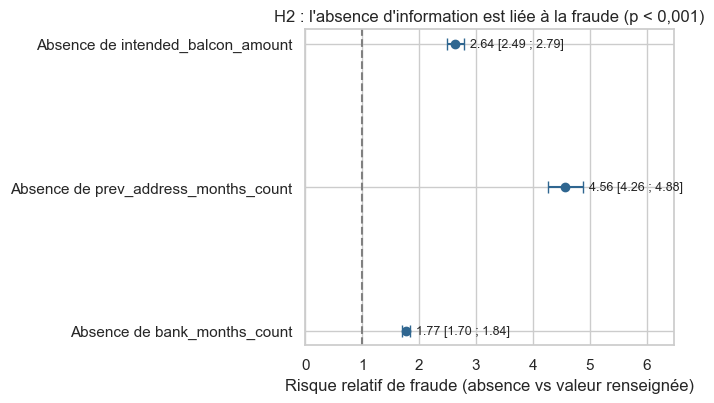

In [36]:
analyser_h2_manquants(df_clean, ['bank_months_count', 'prev_address_months_count', 'intended_balcon_amount'])

##### Résultat H2 (Ancrage) : CONFIRMÉE sous l'angle de l'absence
**Constat** : l'absence de bank_months_count porte le taux de fraude à 1,63 % contre 0,92 % (RR = 1,77, IC 95 % [1,70 ; 1,84]). Pour prev_address_months_count : 1,42 % contre 0,31 % (RR = 4,56, IC [4,26 ; 4,88]).

**Taille d'effet** : modérée pour bank_months_count (×1,8), forte pour prev_address_months_count (×4,6).

**Lecture métier** : c'est une association, pas une preuve de cause. 98,6 % des dossiers sans adresse précédente sont légitimes : ce n'est pas une règle de blocage, mais un signal à combiner avec d'autres.

**Conséquence modèle** : add_indicator=True conserve ce drapeau d'absence. Activation obligatoire de SimpleImputer(add_indicator=True) dans Scikit-Learn pour capturer le drapeau d'absence.

#### Hypothèse 3 : 

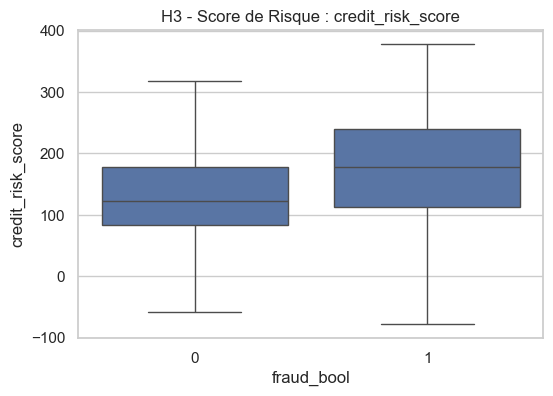

RÉSULTATS : H3 - Score de Risque (credit_risk_score)
Médiane Fraude : 178.00 | Médiane Légitime : 122.00
AUC Mann-Whitney : 0.666 | IC 95 % [0.661 ; 0.672] (0,5 = aucune différence)
d de Cohen : 0.621 | IC 95 % de la différence de moyennes [45.59 ; 48.66]
p-value : 0.00e+00



In [37]:
# Appel unique pour H3 (même fonction qu'en H1)
auc_h3, p_h3 = analyser_distribution_continue(df_clean, 'credit_risk_score', 'H3 - Score de Risque')

##### Résultat H3 (Risque financier) : CONFIRMÉE, effet moyen

**Constat** : moyenne 177,6 (fraude) contre 130,5 (légitime) ; médianes 178 contre 122 ; d = 0,62 ; IC 95 % de la différence [45,6 ; 48,7] ; AUC = 0,67 [0,66 ; 0,67].

**Taille d'effet** : moyen (d > 0,5), le plus fort des 3 tests, mais l'AUC reste modeste : une fraude a 67 % de chances d'avoir un score plus élevé. Le score seul ne suffit pas.

**Disponibilité à t = 0** : la datasheet Feedzai décrit credit_risk_score comme un « score interne de risque de la demande » (plage −191 à 389) mais ne précise pas à quel moment il est calculé. Nous supposons qu'il est connu au dépôt de la demande : hypothèse à confirmer avec la banque. Vérification empirique : sans credit_risk_score ni proposed_credit_limit, la PR-AUC du mois 5 passe de 0,155 à 0,142. Le modèle ne repose pas sur ces deux variables.

**Tests multiples** : 5 tests (H1, H2 × 3, H3) → Bonferroni α = 0,05/5 = 0,01. Toutes les p-values sont très inférieures, l'important reste la taille d'effet.

# 5. Découpage des Données (Temporel)

Afin d'éviter tout risque de fuite temporelle (*data leakage*), nous appliquons un découpage basé sur la variable chronologique `month`. Les premiers mois servent à l'entraînement, et les plus récents forment le jeu de test.

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [39]:
# 1. Découpage temporel strict (Consigne Sujet D)
train_df = df_clean[df_clean['month'] <= 5]
test_df = df_clean[df_clean['month'] > 5]

# 2. Séparation X, y avec exclusion stricte de 'month' et des identifiants
X_train = train_df.drop(columns=['fraud_bool', 'month'])
y_train = train_df['fraud_bool']
X_test = test_df.drop(columns=['fraud_bool', 'month'])
y_test = test_df['fraud_bool']

# Identificateurs des colonnes numériques et catégorielles
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()

# 3. Pipelines de transformation
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

### Justification du Découpage Temporel
En détection de fraude, le modèle doit apprendre du passé pour prédire l'avenir. Un découpage aléatoire standard (Random Split) mélangerait les époques et surestimerait les performances réelles en production. Le taux de fraude passe de 1,03 % (train) à 1,40 % (test) : le test est plus difficile à lire en PR-AUC, d’où la comparaison avec le naïf

## 6. Pipeline de Modélisation & Entraînement

Construction d'un pipeline `scikit-learn` sans fuite de données (imputation avec indicateur de manque, encodage des catégorielles, normalisation) et entraînement du modèle naïf (`DummyClassifier`) ainsi que de la Régression Logistique sur le jeu d'entraînement (`month <= 5`).

In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, auc, confusion_matrix
from sklearn.utils import resample
from sklearn.metrics import average_precision_score, roc_curve 
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

In [41]:
# 1. Pipeline Modèle Naïf (Baseline)
pipe_dummy = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('clf', DummyClassifier(strategy='prior', random_state=42))
])

# 2. Pipeline Régression Logistique (Modèle Principal)
pipe_logreg = Pipeline(steps=[
    ('preprocessor', preprocessor), 
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# 3. Entraînement uniquement sur le jeu de TRAIN (mois 0 à 5)
pipe_dummy.fit(X_train, y_train)
pipe_logreg.fit(X_train, y_train)

print("Modèles entraînés avec succès sur le jeu d'entraînement.")

Modèles entraînés avec succès sur le jeu d'entraînement.


Analyse :
Le DummyClassifier sert de ligne de base (baseline) naïve pour vérifier le gain réel apporté par l'apprentissage.

L'option class_weight='balanced' est appliquée à la Régression Logistique pour compenser le fort déséquilibre de classe (1,03% de fraude sur le train).

## 7. Validation croisée temporelle

In [42]:
def rappel_a_fpr(y, proba, fpr_cible=0.05):
    fpr, tpr, seuils = roc_curve(y, proba)
    i = np.searchsorted(fpr, fpr_cible, side='right') - 1
    return tpr[i], seuils[i]

# Fenêtre croissante : on apprend sur les mois passés, on valide sur le mois suivant
mois = train_df['month'].values
lignes = []
for m_val in [3, 4, 5]:
    i_tr, i_va = np.where(mois < m_val)[0], np.where(mois == m_val)[0]
    modele = clone(pipe_logreg).fit(X_train.iloc[i_tr], y_train.iloc[i_tr])
    proba = modele.predict_proba(X_train.iloc[i_va])[:, 1]
    rappel, _ = rappel_a_fpr(y_train.iloc[i_va], proba)
    lignes.append({'mois validé': m_val, 'taux de fraude %': y_train.iloc[i_va].mean() * 100,
                   'PR-AUC': average_precision_score(y_train.iloc[i_va], proba), 'rappel @FPR 5 %': rappel})
cv = pd.DataFrame(lignes).round(3)
print(cv)
print(f"PR-AUC moyenne : {cv['PR-AUC'].mean():.3f} (+/- {cv['PR-AUC'].std():.3f})")

# Dépendance à credit_risk_score et proposed_credit_limit (validation sur le mois 5, pas sur le test)
exclus = ['credit_risk_score', 'proposed_credit_limit']
num_sans = [c for c in num_cols if c not in exclus]
prep_sans = ColumnTransformer([('num', num_transformer, num_sans), ('cat', cat_transformer, cat_cols)])
pipe_sans = Pipeline([('preprocessor', prep_sans),
                      ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))])
i_tr, i_va = np.where(mois < 5)[0], np.where(mois == 5)[0]
Xs = X_train.drop(columns=exclus)
p_sans = pipe_sans.fit(Xs.iloc[i_tr], y_train.iloc[i_tr]).predict_proba(Xs.iloc[i_va])[:, 1]
print(f"Sans ces 2 variables (mois 5) : PR-AUC = {average_precision_score(y_train.iloc[i_va], p_sans):.3f}")

   mois validé  taux de fraude %  PR-AUC  rappel @FPR 5 %
0            3             0.922   0.136            0.540
1            4             1.137   0.146            0.531
2            5             1.183   0.155            0.510
PR-AUC moyenne : 0.146 (+/- 0.010)
Sans ces 2 variables (mois 5) : PR-AUC = 0.142


**Justification** : PR-AUC 0,136 / 0,146 / 0,155 selon le mois validé, donc stable.

## 8. Calibrage du Seuil Métier sur le Train

Détermination du seuil de décision optimal sur le jeu d'entraînement uniquement, afin de garantir un Taux de Faux Positifs contrôlé ($\text{FPR} \le 5\%$) conformément aux contraintes opérationnelles de la banque.

Seuil sélectionné sur Train (pour FPR <= 5%) : 0.81


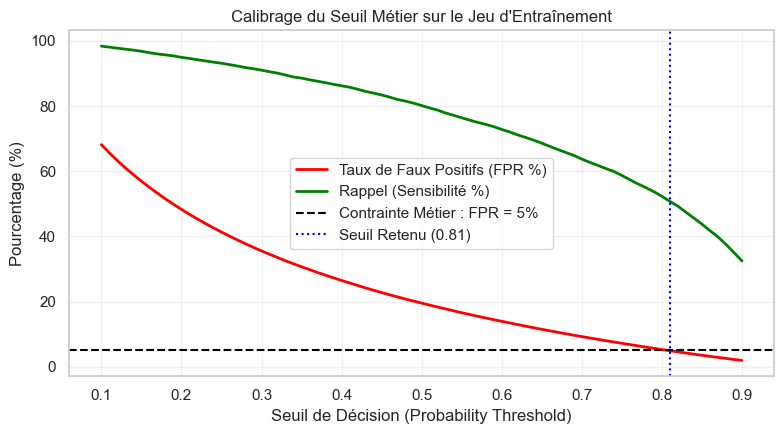

In [43]:
# Calcul des probabilités uniquement sur TRAIN (anti-leakage)
y_probas_train = pipe_logreg.predict_proba(X_train)[:, 1]

# Balayage des seuils
thresholds = np.linspace(0.1, 0.9, 81)
fpr_list = []
recall_list = []

neg_mask_train = (y_train == 0)
pos_mask_train = (y_train == 1)

for th in thresholds:
    fpr_tmp = ((y_probas_train >= th) & neg_mask_train).sum() / neg_mask_train.sum()
    rec_tmp = ((y_probas_train >= th) & pos_mask_train).sum() / pos_mask_train.sum()
    fpr_list.append(fpr_tmp)
    recall_list.append(rec_tmp)

# Recherche automatique du seuil FPR <= 5%
threshold_5fpr = 0.5
for th, fpr in zip(thresholds, fpr_list):
    if fpr <= 0.05:
        threshold_5fpr = th
        break

print(f"Seuil sélectionné sur Train (pour FPR <= 5%) : {threshold_5fpr:.2f}")

# --- Graphique de Calibrage ---
plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, [f * 100 for f in fpr_list], label='Taux de Faux Positifs (FPR %)', color='red', lw=2)
plt.plot(thresholds, [r * 100 for r in recall_list], label='Rappel (Sensibilité %)', color='green', lw=2)

plt.axhline(y=5, color='black', linestyle='--', label='Contrainte Métier : FPR = 5%')
plt.axvline(x=threshold_5fpr, color='blue', linestyle=':', label=f'Seuil Retenu ({threshold_5fpr:.2f})')

plt.xlabel('Seuil de Décision (Probability Threshold)')
plt.ylabel('Pourcentage (%)')
plt.title('Calibrage du Seuil Métier sur le Jeu d\'Entraînement')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Règle** : le seuil est calibré sur le train, jamais sur le test. Contrainte : FPR ≤ 5 % (la banque ne revoit pas plus de 5 % des dossiers légitimes).

**Limite** : calibré sur des scores issus d'un modèle déjà ajusté sur ces données, il est un peu optimiste. Le FPR n'est pas « garanti » : au test il est de 3,6 %, donc prudent, au prix d'un rappel plus bas. Un seuil calibré sur le mois 5 donnait à l'inverse ≈ 6 % de FPR au test : les scores dérivent d'un mois à l'autre, point à reprendre en module 4.

## 9. Évaluation Finale sur le Test & Intervalles de Confiance

Évaluation unique sur le jeu de test (`month > 5`), comparaison de la PR-AUC avec la baseline naïve, calcul du Rappel réel au seuil métier et estimation de l'intervalle de confiance à 95 % par bootstrap (500 itérations).

In [44]:
proba_test = pipe_logreg.predict_proba(X_test)[:, 1]
proba_dummy = pipe_dummy.predict_proba(X_test)[:, 1]
pr_model = average_precision_score(y_test, proba_test)
pr_dummy = average_precision_score(y_test, proba_dummy)       # = prévalence du test
pred = (proba_test >= threshold_5fpr)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

rng = np.random.default_rng(42)
yt = y_test.values
b_mod, b_dum, b_rec, b_fpr = [], [], [], []
for _ in range(500):
    idx = rng.integers(0, len(yt), len(yt))
    y_b = yt[idx]
    b_mod.append(average_precision_score(y_b, proba_test[idx]))
    b_dum.append(average_precision_score(y_b, proba_dummy[idx]))
    b_rec.append(pred[idx][y_b == 1].mean())
    b_fpr.append(pred[idx][y_b == 0].mean())
ic = lambda v: np.percentile(v, [2.5, 97.5])

print(f"Seuil retenu (calibré sur le train) : {threshold_5fpr:.2f}")
print(f"PR-AUC naïf : {pr_dummy:.4f} | IC 95 % [{ic(b_dum)[0]:.4f} ; {ic(b_dum)[1]:.4f}]")
print(f"PR-AUC régression logistique : {pr_model:.4f} | IC 95 % [{ic(b_mod)[0]:.4f} ; {ic(b_mod)[1]:.4f}]")
print(f"Rappel au seuil : {tp/(tp+fn)*100:.1f} % | IC 95 % [{ic(b_rec)[0]*100:.1f} ; {ic(b_rec)[1]*100:.1f}]")
print(f"FPR au seuil : {fp/(fp+tn)*100:.2f} % | IC 95 % [{ic(b_fpr)[0]*100:.2f} ; {ic(b_fpr)[1]*100:.2f}]")
print(f"Précision au seuil : {tp/(tp+fp)*100:.1f} %  -> {fp/tp:.1f} clients légitimes contrôlés par fraude détectée")

Seuil retenu (calibré sur le train) : 0.81
PR-AUC naïf : 0.0140 | IC 95 % [0.0136 ; 0.0145]
PR-AUC régression logistique : 0.1643 | IC 95 % [0.1518 ; 0.1777]
Rappel au seuil : 44.3 % | IC 95 % [42.3 ; 46.1]
FPR au seuil : 3.60 % | IC 95 % [3.53 ; 3.68]
Précision au seuil : 14.9 %  -> 5.7 clients légitimes contrôlés par fraude détectée


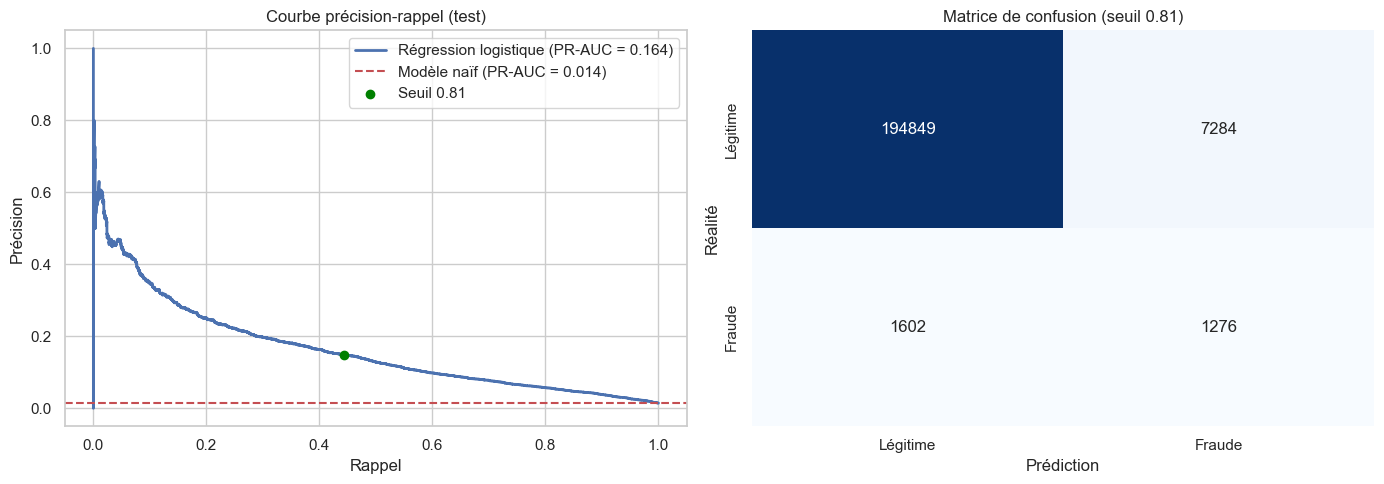

In [45]:
p_m, r_m, _ = precision_recall_curve(y_test, proba_test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(r_m, p_m, lw=2, label=f'Régression logistique (PR-AUC = {pr_model:.3f})')
axes[0].axhline(pr_dummy, color='r', ls='--', label=f'Modèle naïf (PR-AUC = {pr_dummy:.3f})')
axes[0].scatter([tp / (tp + fn)], [tp / (tp + fp)], color='green', zorder=5, label=f'Seuil {threshold_5fpr:.2f}')
axes[0].set(xlabel='Rappel', ylabel='Précision', title='Courbe précision-rappel (test)')
axes[0].legend()
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Légitime', 'Fraude'], yticklabels=['Légitime', 'Fraude'])
axes[1].set(xlabel='Prédiction', ylabel='Réalité', title=f'Matrice de confusion (seuil {threshold_5fpr:.2f})')
plt.tight_layout()
plt.show()

**Face au modèle naïf** : PR-AUC 0,164 [0,152 ; 0,178] contre 0,014 [0,014 ; 0,015] (= la prévalence) : environ 12 fois mieux, IC disjoints.

**Au seuil retenu (0,81)** : rappel ≈ 44 % [42 ; 46], FPR ≈ 3,6 %, précision ≈ 15 % : environ 6 clients légitimes contrôlés pour une fraude détectée.

**Objectif du Canvas** (rappel >> 50 % à FPR 5 %) : non atteint. Le rappel est estimé sur 2 878 fraudes seulement (± 1,8 pt).
**Pistes pour le module 3** : un modèle d'arbres pourrait capter des interactions qu'un modèle linéaire ne voit pas : c'est une hypothèse à tester, pas un résultat acquis.

## 10. Marge d'erreur du TCL

In [46]:
import joblib, json
from pathlib import Path

In [47]:
n_test, n_fraudes = len(y_test), int(y_test.sum())
p_hat = n_fraudes / n_test
marge_taux = 1.96 * np.sqrt(p_hat * (1 - p_hat) / n_test)
rappel_obs = tp / (tp + fn)
marge_rappel = 1.96 * np.sqrt(rappel_obs * (1 - rappel_obs) / n_fraudes)
print(f"Test : {n_fraudes} fraudes sur {n_test} dossiers -> taux {p_hat*100:.2f} % (+/- {marge_taux*100:.2f} pt)")
print(f"Le rappel repose sur {n_fraudes} fraudes : {rappel_obs*100:.1f} % (+/- {marge_rappel*100:.1f} pt)")

Path('../models').mkdir(exist_ok=True)
joblib.dump(pipe_logreg, '../models/pipeline_reference.joblib')
json.dump({'seuil': float(threshold_5fpr), 'fpr_cible': 0.05}, open('../models/seuil.json', 'w'))

Test : 2878 fraudes sur 205011 dossiers -> taux 1.40 % (+/- 0.05 pt)
Le rappel repose sur 2878 fraudes : 44.3 % (+/- 1.8 pt)


#### Annexe : Usage de l'IA 


l'IA a été utilisée pour une partie du code (validation croisée temporelle, bootstrap), pour relire le notebook et en signaler les erreurs, et pour améliorer la rédaction de certains paragraphes. Cependant, l'IA a produit ou laissé passer des erreurs que nous avons corrigées (conclusion contraire au résultat sur H1, chiffres obsolètes dans la synthèse, seuil mal justifié).